# Experiment 1 — Early-life timelines of reference accounts

**Question:** do the watchlist (reference) accounts share a *staging phase* early in life —
seed deposit → quiet period with charges eating the balance → sudden "awakening" — and is that
phase rarer among ordinary accounts? Or is FRONTIER a one-off?

**Scope and safety**
- Read-only. Separate from `aml_screening.py`; writes nothing to the reporting DB. Outputs go to `outputs/early_signals/`.
- Same source as production (`HIST_TRAN_DTL_TABLE` × `GENERAL_ACCT_MAST_TABLE`, USD, opened ≥ 2024-01-01, closed included).
- **Difference from production:** charges (`RPT_CODE` CHG/INT) and GL legs are *kept as separate streams* instead of dropped,
  because the staging signal is made of exactly those transactions.
- Time axis is **days since `ACCT_OPN_DATE`** (not calendar time, and not the pipeline's `account_age_days`).

**How to run:** leave `SYNTHETIC = True` to dry-run end to end on generated data. Set it to `False` to run on real data;
connections use the production `.env` (`AML_READ_*` for Finacle, `AML_WRITE_*` for the reporting DB) — set `ENV_FILE` if
the notebook isn't in the same folder as `.env`.

**Gate at the end:** decide whether Experiment 2 (staging features) is worth building.

In [7]:
import re
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SYNTHETIC = False          # False = real data via get_engines()

WINDOW_DAYS     = 180     # early-life window, in days since opening
EARLY_DAYS      = 90      # sub-window for the charge-share metric
QUIET_MIN_DAYS  = 30      # minimum silence before an awakening to count as "staging"
AWAKE_WINDOW    = 7       # awakening = first 7-day window carrying...
AWAKE_SHARE     = 0.25    # ...at least 25% of the account's window turnover
BASELINE_N      = 200     # random unflagged comparison accounts
RANDOM_SEED     = 42
FOCUS_NAME      = "FRONTIER"   # account name substring to inspect in detail

AS_OF = pd.Timestamp.today().normalize()
OUT = Path("outputs/early_signals"); OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 40)

## 1. Connections and queries

In [8]:
import os

# Same .env as production. Point ENV_FILE at it if the notebook runs from another folder.
ENV_FILE = ".env"
try:
    from dotenv import load_dotenv
    load_dotenv(ENV_FILE, override=False)
except ImportError:
    print("python-dotenv not installed; relying on variables already in the environment")

def _engine(prefix):
    '''Copied from aml_screening.py so the experiment doesn't import (or depend on) the production script.
    READ = Finacle, WRITE = reporting DB (used here for SELECTs only; the notebook writes nothing).'''
    from sqlalchemy import create_engine, URL

    full_url = os.environ.get(f"AML_{prefix}_URL")
    if full_url:
        return create_engine(full_url, fast_executemany=True)

    def req(name):
        val = os.environ.get(f"AML_{prefix}_{name}")
        if not val:
            raise RuntimeError(f"Set AML_{prefix}_{name} (or provide a full AML_{prefix}_URL)")
        return val

    url = URL.create(
        "mssql+pyodbc",
        username=req("USER"),
        password=req("PWD"),
        host=req("HOST"),
        port=int(os.environ.get(f"AML_{prefix}_PORT", "1433")),
        database=req("DB"),
        query={"driver": os.environ.get("AML_ODBC_DRIVER", "ODBC Driver 17 for SQL Server")},
    )
    return create_engine(url, fast_executemany=True)

def get_engines():
    '''Return (finacle_engine, reporting_engine).'''
    return _engine("READ"), _engine("WRITE")

FIN = "RSVRRealtimeFinacleUGPRD.TBAADM"

# Population for the baseline: same filters as production, accounts with at least one transaction.
POPULATION_SQL = f'''
SELECT gm.ACID, gm.ACCT_OPN_DATE
FROM {FIN}.GENERAL_ACCT_MAST_TABLE gm
WHERE gm.ACCT_CRNCY_CODE = 'USD'
  AND gm.ACCT_OPN_DATE >= '2024-01-01'
  AND EXISTS (SELECT 1 FROM {FIN}.HIST_TRAN_DTL_TABLE hd WHERE hd.ACID = gm.ACID)
'''

MASTER_SQL = f'''
SELECT ACID, ACCT_NAME, FORACID, CIF_ID, ACCT_OPN_DATE, ACCT_CLS_FLG, ACCT_CRNCY_CODE
FROM {FIN}.GENERAL_ACCT_MAST_TABLE
WHERE ACID IN ({{ids}})
'''

# Production EXTRACT_QUERY columns, restricted to the sampled ACIDs.
TXN_SQL = f'''
SELECT gm.ACID, gm.ACCT_OPN_DATE,
       hd.TRAN_DATE, hd.TRAN_ID, hd.TRAN_AMT, hd.TRAN_PARTICULAR, hd.TRAN_RMKS,
       hd.PART_TRAN_TYPE, hd.TRAN_TYPE, hd.TRAN_SUB_TYPE, hd.RCRE_TIME, hd.RPT_CODE
FROM {FIN}.HIST_TRAN_DTL_TABLE hd
JOIN {FIN}.GENERAL_ACCT_MAST_TABLE gm ON hd.ACID = gm.ACID
WHERE hd.ACID IN ({{ids}})
'''

def _in_list(ids):
    bad = [i for i in ids if not re.fullmatch(r"[A-Za-z0-9]+", str(i))]
    if bad:
        raise ValueError(f"Unexpected ACID format: {bad[:5]}")
    return ",".join(f"'{i}'" for i in ids)

def read_in_chunks(sql_template, ids, eng, chunk=500):
    ids = list(dict.fromkeys(ids))
    parts = [pd.read_sql(sql_template.format(ids=_in_list(ids[i:i+chunk])), eng)
             for i in range(0, len(ids), chunk)]
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

## 2. Synthetic data (dry-run only)

In [9]:
def make_synthetic(n_ref=10, n_pop=1200, seed=7):
    '''Fake GAM + HTD rows with the production column names. Not evidence of anything.'''
    rng = np.random.default_rng(seed)
    acct_rows, txn_rows = [], []
    tid = [0]

    def add(acid, opn, day, amt, ptt, part="TRF", rpt=None):
        tid[0] += 1
        when = opn + pd.Timedelta(days=int(day))
        txn_rows.append(dict(ACID=acid, ACCT_OPN_DATE=opn, TRAN_DATE=when, TRAN_ID=f"T{tid[0]}",
                             TRAN_AMT=round(float(amt), 2), TRAN_PARTICULAR=part, TRAN_RMKS=None,
                             PART_TRAN_TYPE=ptt, TRAN_TYPE="T", TRAN_SUB_TYPE="CI",
                             RCRE_TIME=when, RPT_CODE=rpt))

    def monthly_charges(acid, opn, upto):
        for d in range(30, upto, 30):
            add(acid, opn, d, rng.uniform(8, 25), "D", "MAINTENANCE CHARGE", "CHG")

    def staging(acid, opn):
        seed_day = rng.integers(1, 12)
        add(acid, opn, seed_day, rng.uniform(300, 2000), "C", "CASH DEPOSIT")
        wake = seed_day + rng.integers(40, 110)
        monthly_charges(acid, opn, wake)
        burst(acid, opn, wake)

    def burst(acid, opn, start, k=None):
        for _ in range(k or rng.integers(8, 20)):
            d = start + rng.integers(0, 25)
            amt = rng.uniform(5_000, 60_000)
            add(acid, opn, d, amt, "C", f"INWARD TT {rng.integers(100,999)}")
            add(acid, opn, d + rng.integers(0, 2), amt * rng.uniform(0.9, 1.0), "D", "OUTWARD TT")

    def business(acid, opn):
        for d in sorted(rng.integers(0, 400, rng.integers(30, 120))):
            add(acid, opn, d, rng.uniform(200, 15_000), rng.choice(["C", "D"], p=[.52, .48]), "INVOICE")
        monthly_charges(acid, opn, 400)
        if rng.random() < .3:
            add(acid, opn, rng.integers(5, 200), rng.uniform(100, 900), "C", "AC XFR FROM GL 0603 ADJ")

    def dormant(acid, opn):
        add(acid, opn, rng.integers(0, 20), rng.uniform(100, 1500), "C", "CASH DEPOSIT")
        monthly_charges(acid, opn, 400)

    for i in range(n_ref + n_pop):
        is_ref = i < n_ref
        acid = f"SY{i:06d}"
        opn = pd.Timestamp("2024-01-01") + pd.Timedelta(days=int(rng.integers(0, 520)))
        if is_ref:
            name = "SYNTHETIC FRONTIER-LIKE LTD" if i == 0 else f"SYNTHETIC REF {i:02d}"
            (staging if i < 6 else (lambda a, o: burst(a, o, rng.integers(2, 15))))(acid, opn)
        else:
            name = f"SYNTHETIC POP {i:05d}"
            r = rng.random()
            if r < .75:   business(acid, opn)
            elif r < .93: dormant(acid, opn)
            else:         staging(acid, opn)      # legitimate accounts can look like this too
        acct_rows.append(dict(ACID=acid, ACCT_NAME=name, FORACID=f"9{i:09d}", CIF_ID=f"C{i:07d}",
                              ACCT_OPN_DATE=opn, ACCT_CLS_FLG="N", ACCT_CRNCY_CODE="USD"))

    master = pd.DataFrame(acct_rows)
    txns = pd.DataFrame(txn_rows)
    txns = txns[txns.TRAN_DATE <= AS_OF]
    watchlist = master.ACID.iloc[:n_ref].tolist()
    return master, txns, watchlist

## 3. Load reference accounts and a random baseline

In [12]:
rng = np.random.default_rng(RANDOM_SEED)

if SYNTHETIC:
    syn_master, syn_txns, watchlist = make_synthetic()
    population = syn_master[["ACID", "ACCT_OPN_DATE"]]
else:
    fin_eng, rep_eng = get_engines()
    watchlist = pd.read_sql("SELECT acid FROM aml_watchlist WHERE active = 1", rep_eng)["acid"].tolist()
    population = pd.read_sql(POPULATION_SQL, fin_eng)

population = population.assign(ACCT_OPN_DATE=pd.to_datetime(population.ACCT_OPN_DATE))
population["observed_days"] = (AS_OF - population.ACCT_OPN_DATE).dt.days

# Baseline: unflagged accounts old enough to show the whole window (no right-censoring).
eligible = population[~population.ACID.isin(watchlist) & (population.observed_days >= WINDOW_DAYS)]
baseline_ids = eligible.sample(n=min(BASELINE_N, len(eligible)), random_state=RANDOM_SEED).ACID.tolist()
ids = list(watchlist) + baseline_ids

if SYNTHETIC:
    master = syn_master[syn_master.ACID.isin(ids)].copy()
    raw = syn_txns[syn_txns.ACID.isin(ids)].copy()
else:
    master = read_in_chunks(MASTER_SQL, ids, fin_eng)
    raw = read_in_chunks(TXN_SQL, ids, fin_eng)

master["ACCT_OPN_DATE"] = pd.to_datetime(master.ACCT_OPN_DATE)
master["group"] = np.where(master.ACID.isin(watchlist), "reference", "baseline")
master["observed_days"] = (AS_OF - master.ACCT_OPN_DATE).dt.days.clip(upper=WINDOW_DAYS)

print(f"Reference accounts: {len(watchlist)} on watchlist, {master.group.eq('reference').sum()} found in master")
print(f"Baseline accounts:  {len(baseline_ids)} sampled from {len(eligible):,} eligible")
print(f"Transactions pulled: {len(raw):,}")
short = master[(master.group == 'reference') & (master.observed_days < WINDOW_DAYS)]
if len(short):
    print(f"Note: {len(short)} reference account(s) younger than {WINDOW_DAYS} days — window is partial.")
non_usd = master[(master.group == 'reference') & (master.ACCT_CRNCY_CODE != 'USD')]
if len(non_usd):
    print(f"Note: {len(non_usd)} reference account(s) are not USD.")

Reference accounts: 10 on watchlist, 10 found in master
Baseline accounts:  200 sampled from 21,038 eligible
Transactions pulled: 26,427
Note: 1 reference account(s) younger than 180 days — window is partial.


## 4. Classify streams (charges and GL legs kept, not dropped)

Same rules as production `clean_transactions`: charge = `RPT_CODE` in CHG/INT; GL leg = narration matches `GL <digits>`.
Charge takes precedence where both match.

In [13]:
def classify(df):
    df = df.copy()
    for col in ("TRAN_DATE", "ACCT_OPN_DATE", "RCRE_TIME"):
        df[col] = pd.to_datetime(df[col], errors="coerce")
    part = df["TRAN_PARTICULAR"].fillna("").str.upper()
    rpt = df["RPT_CODE"].fillna("").str.upper()
    is_charge = rpt.isin(["CHG", "INT"])
    is_gl = part.str.contains(r"\bGL\s*\d", regex=True)
    df["stream"] = np.select([is_charge, is_gl], ["charge", "gl"], "customer")
    df["dir"] = df["PART_TRAN_TYPE"].str.upper().str.strip().map({"C": "cr", "D": "dr"})
    df["TRAN_AMT"] = df["TRAN_AMT"].astype(float).abs()
    df["signed"] = np.where(df["dir"] == "cr", df["TRAN_AMT"], -df["TRAN_AMT"])
    df["day"] = (df["TRAN_DATE"].dt.normalize() - df["ACCT_OPN_DATE"].dt.normalize()).dt.days
    return df

tx = classify(raw)
pre = (tx.day < 0).sum(); bad_dir = tx.dir.isna().sum()
print(f"Dropped: {pre} txns dated before opening, {bad_dir} with unknown PART_TRAN_TYPE")
tx = tx[(tx.day >= 0) & tx.dir.notna()]
print(tx.groupby(["stream", "dir"]).TRAN_AMT.agg(["count", "sum"]).round(0))

Dropped: 0 txns dated before opening, 0 with unknown PART_TRAN_TYPE
              count          sum
stream   dir                    
charge   cr      80      29693.0
         dr    4160     139109.0
customer cr    5738  199853575.0
         dr   16223  197604337.0
gl       cr     113     420506.0
         dr     113     420506.0


## 5. Daily timelines

One row per account per day from opening. Balance is reconstructed from cumulative flows across **all** streams
(customer + charges + GL), starting from zero at opening — valid because no transactions predate opening.

In [14]:
def daily_timeline(tx_acct, n_days):
    t = tx_acct[tx_acct.day < n_days]
    piv = (t.assign(col=t.stream + "_" + t.dir)
             .pivot_table(index="day", columns="col", values="TRAN_AMT", aggfunc="sum", fill_value=0))
    cnt = t[t.stream == "customer"].groupby("day").size().rename("cust_n")
    d = pd.DataFrame(index=pd.RangeIndex(n_days, name="day")).join(piv).join(cnt).fillna(0)
    for c in ["customer_cr", "customer_dr", "charge_cr", "charge_dr", "gl_cr", "gl_dr"]:
        if c not in d:
            d[c] = 0.0
    d["net"] = d.customer_cr + d.charge_cr + d.gl_cr - d.customer_dr - d.charge_dr - d.gl_dr
    d["balance"] = d.net.cumsum()
    d["cust_turnover"] = d.customer_cr + d.customer_dr
    return d

timelines = {}
for acid, row in master.set_index("ACID").iterrows():
    timelines[acid] = daily_timeline(tx[tx.ACID == acid], int(max(row.observed_days, 1)))
print(f"Built {len(timelines)} timelines")

Built 210 timelines


## 6. Early-life metrics per account

| metric | meaning |
|---|---|
| `first_cr_day`, `first_cr_amt` | first customer credit |
| `first_dr_day` | first customer-initiated debit |
| `cr_to_dr_gap` | days from first credit to first debit |
| `active_days` | days with any customer transaction |
| `turnover_first30_share` | share of window turnover in days 0–29 (low = back-loaded) |
| `charge_share_early` | charges ÷ all debits in the first `EARLY_DAYS` days |
| `fee_erosion` | charges before first customer debit ÷ first credit |
| `longest_quiet` | longest silence between opening and the last customer transaction (trailing silence ignored, so early closures don't inflate it) |
| `awakening_day` | start of the activity run containing the first `AWAKE_WINDOW`-day window that carries ≥ `AWAKE_SHARE` of window turnover |
| `quiet_before_awake` | silence immediately before the awakening |
| `staging` | seeded before awakening **and** quiet ≥ `QUIET_MIN_DAYS` before it |

In [15]:
def early_metrics(d):
    m = {}
    cust = d.cust_n > 0
    cr_days = d.index[d.customer_cr > 0]
    dr_days = d.index[d.customer_dr > 0]
    total = d.cust_turnover.sum()

    m["first_cr_day"] = cr_days[0] if len(cr_days) else np.nan
    m["first_cr_amt"] = d.customer_cr.iloc[cr_days[0]] if len(cr_days) else np.nan
    m["first_dr_day"] = dr_days[0] if len(dr_days) else np.nan
    m["cr_to_dr_gap"] = m["first_dr_day"] - m["first_cr_day"]
    m["active_days"] = int(cust.sum())
    m["turnover_window"] = total
    m["turnover_first30_share"] = d.cust_turnover.iloc[:30].sum() / total if total else np.nan

    early = d.iloc[:EARLY_DAYS]
    debits = early.charge_dr.sum() + early.customer_dr.sum()
    m["charge_share_early"] = early.charge_dr.sum() / debits if debits else np.nan

    upto = int(m["first_dr_day"]) if len(dr_days) else len(d)
    m["fee_erosion"] = d.charge_dr.iloc[:upto].sum() / m["first_cr_amt"] if m["first_cr_amt"] else np.nan

    act = np.flatnonzero(cust.values)
    if len(act):
        gaps = np.diff(np.concatenate([[-1], act])) - 1      # includes opening -> first activity
        m["longest_quiet"] = int(gaps.max())
    else:
        m["longest_quiet"] = np.nan

    m["awakening_day"] = m["quiet_before_awake"] = np.nan
    m["staging"] = False
    if total:
        fwd = d.cust_turnover[::-1].rolling(AWAKE_WINDOW, min_periods=1).sum()[::-1]
        hit = np.flatnonzero(fwd.values >= AWAKE_SHARE * total)
        if len(hit):
            a = int(hit[0])
            first_in = a + int(np.flatnonzero(cust.values[a:])[0])   # first active day in that window
            # walk back to the start of the activity run (no gap longer than AWAKE_WINDOW days)
            i = int(np.searchsorted(act, first_in))
            while i > 0 and act[i] - act[i - 1] <= AWAKE_WINDOW:
                i -= 1
            first_in = int(act[i])
            prior = act[act < first_in]
            m["awakening_day"] = first_in
            m["quiet_before_awake"] = first_in - (prior[-1] + 1 if len(prior) else 0)
            seeded = len(cr_days) and cr_days[0] < first_in
            m["staging"] = bool(seeded and m["quiet_before_awake"] >= QUIET_MIN_DAYS)
    return m

summary = (pd.DataFrame({a: early_metrics(d) for a, d in timelines.items()}).T
             .rename_axis("ACID").reset_index()
             .merge(master[["ACID", "ACCT_NAME", "FORACID", "CIF_ID", "ACCT_OPN_DATE", "ACCT_CLS_FLG",
                            "group", "observed_days"]], on="ACID"))
summary["staging"] = summary.staging.astype(bool)
print(summary.groupby("group").size())

group
baseline     200
reference     10
dtype: int64


## 7. Reference vs baseline

In [16]:
METRICS = ["first_cr_day", "first_dr_day", "cr_to_dr_gap", "active_days", "turnover_first30_share",
           "charge_share_early", "fee_erosion", "longest_quiet", "awakening_day", "quiet_before_awake"]

ref = summary[summary.group == "reference"]
base = summary[summary.group == "baseline"]

def q(s, p):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return s.quantile(p) if len(s) else np.nan

comp = pd.DataFrame({
    "ref_median":  [q(ref[m], .5) for m in METRICS],
    "base_p25":    [q(base[m], .25) for m in METRICS],
    "base_median": [q(base[m], .5) for m in METRICS],
    "base_p75":    [q(base[m], .75) for m in METRICS],
    "ref_n":       [ref[m].notna().sum() for m in METRICS],
}, index=METRICS).round(2)
display(comp)

def hypergeom_upper(k, n_ref, K, N):
    '''P(X >= k): chance of at least k staging accounts among the reference group if they were drawn at random.'''
    return sum(comb(K, x) * comb(N - K, n_ref - x) for x in range(k, min(K, n_ref) + 1)) / comb(N, n_ref)

k, n1 = int(ref.staging.sum()), len(ref)
kb, n0 = int(base.staging.sum()), len(base)
p = hypergeom_upper(k, n1, k + kb, n1 + n0)
print(f"Staging pattern: reference {k}/{n1} ({k/max(n1,1):.0%})  vs  baseline {kb}/{n0} ({kb/max(n0,1):.0%})")
print(f"One-sided exact p = {p:.4f}  (directional only with n ≈ {n1})")

,ref_median,base_p25,base_median,base_p75,ref_n
first_cr_day,0.0,0.00,0.00,1.00,10
first_dr_day,0.0,0.00,0.00,3.00,10
cr_to_dr_gap,0.0,0.00,0.00,1.00,10
active_days,63.0,2.00,7.00,16.25,10
turnover_first30_share,0.1,0.18,0.51,0.98,10
charge_share_early,0.0,0.00,0.00,0.01,10
fee_erosion,0.0,0.00,0.00,0.00,10
longest_quiet,29.5,19.75,30.00,44.25,10
awakening_day,38.0,0.00,0.00,30.75,4
quiet_before_awake,17.0,0.00,0.00,11.75,4


Staging pattern: reference 0/10 (0%)  vs  baseline 14/200 (7%)
One-sided exact p = 1.0000  (directional only with n ≈ 10)


**Where each reference account sits in the baseline distribution** (percentile of the baseline at or below the
account's value). Values near 0 or 100 are unusual relative to ordinary accounts.

In [17]:
def pct_rank(v, s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return np.nan if pd.isna(v) or not len(s) else round(100 * (s <= v).mean())

ref_view = ref[["ACCT_NAME", "FORACID", "staging", "observed_days"] + METRICS].copy()
for m in ["charge_share_early", "fee_erosion", "longest_quiet", "turnover_first30_share", "quiet_before_awake"]:
    ref_view[m + "_pctile"] = [pct_rank(v, base[m]) for v in ref[m]]
display(ref_view.sort_values("staging", ascending=False).round(2))

,ACCT_NAME,FORACID,staging,observed_days,first_cr_day,first_dr_day,cr_to_dr_gap,active_days,turnover_first30_share,charge_share_early,fee_erosion,longest_quiet,awakening_day,quiet_before_awake,charge_share_early_pctile,fee_erosion_pctile,longest_quiet_pctile,turnover_first30_share_pctile,quiet_before_awake_pctile
15,EMIC VENTURES,9030025905260,False,180,0,17,17,72,0.000011,0.000134,0.0,27,NaN,NaN,49,98,40,2,NaN
16,NEBULACORE INNOVATIONS LIMITED,9030025978926,False,180,0,0,0,57,0.308152,0.000891,0.0,30,NaN,NaN,54,98,58,33,NaN
24,FRONTIER TEXTILE DEALERS CO LIMITED,9030027282317,False,180,0,0,0,16,0.000062,0.797462,0.0,31,142,27,96,98,62,2,89.0
50,KWELIVEST INVESTMENT SMC LIMITED,9030025978918,False,180,1,1,0,53,0.000036,0.001256,0.0,28,61,28,56,98,42,2,89.0
54,SHAUPAM ENTERPRISES LIMITED,9030026332531,False,180,0,0,0,142,0.206957,0.000032,0.0,3,NaN,NaN,48,98,14,27,NaN
82,RAVO TECH COMPANY SMC LIMITED,9030028241746,False,159,0,0,0,25,0.69018,0.00068,0.0,30,0,0,53,98,58,57,57.0
91,PACIFIC PRINCE INTERNATIONAL (U) CO. LIMITED,9030025308521,False,180,0,0,0,69,0.00001,0.002734,0.0,31,NaN,NaN,61,98,62,2,NaN
94,HESHIMA PRIME LOGISTICS LTD,9030025725963,False,180,1,3,2,110,0.049835,0.00007,0.0,14,NaN,NaN,49,98,18,16,NaN
96,AETHERGRID TECHNOLOGIES LIMITED,9030025978896,False,180,0,0,0,71,0.146489,0.000725,0.0,29,NaN,NaN,53,98,46,24,NaN
181,OMOSPIRE UGANDA LIMITED,9030027884430,False,180,0,0,0,20,0.358844,0.000624,0.0,30,15,7,53,98,58,35,70.0


## 8. Timelines — small multiples (same day-since-opening axis)

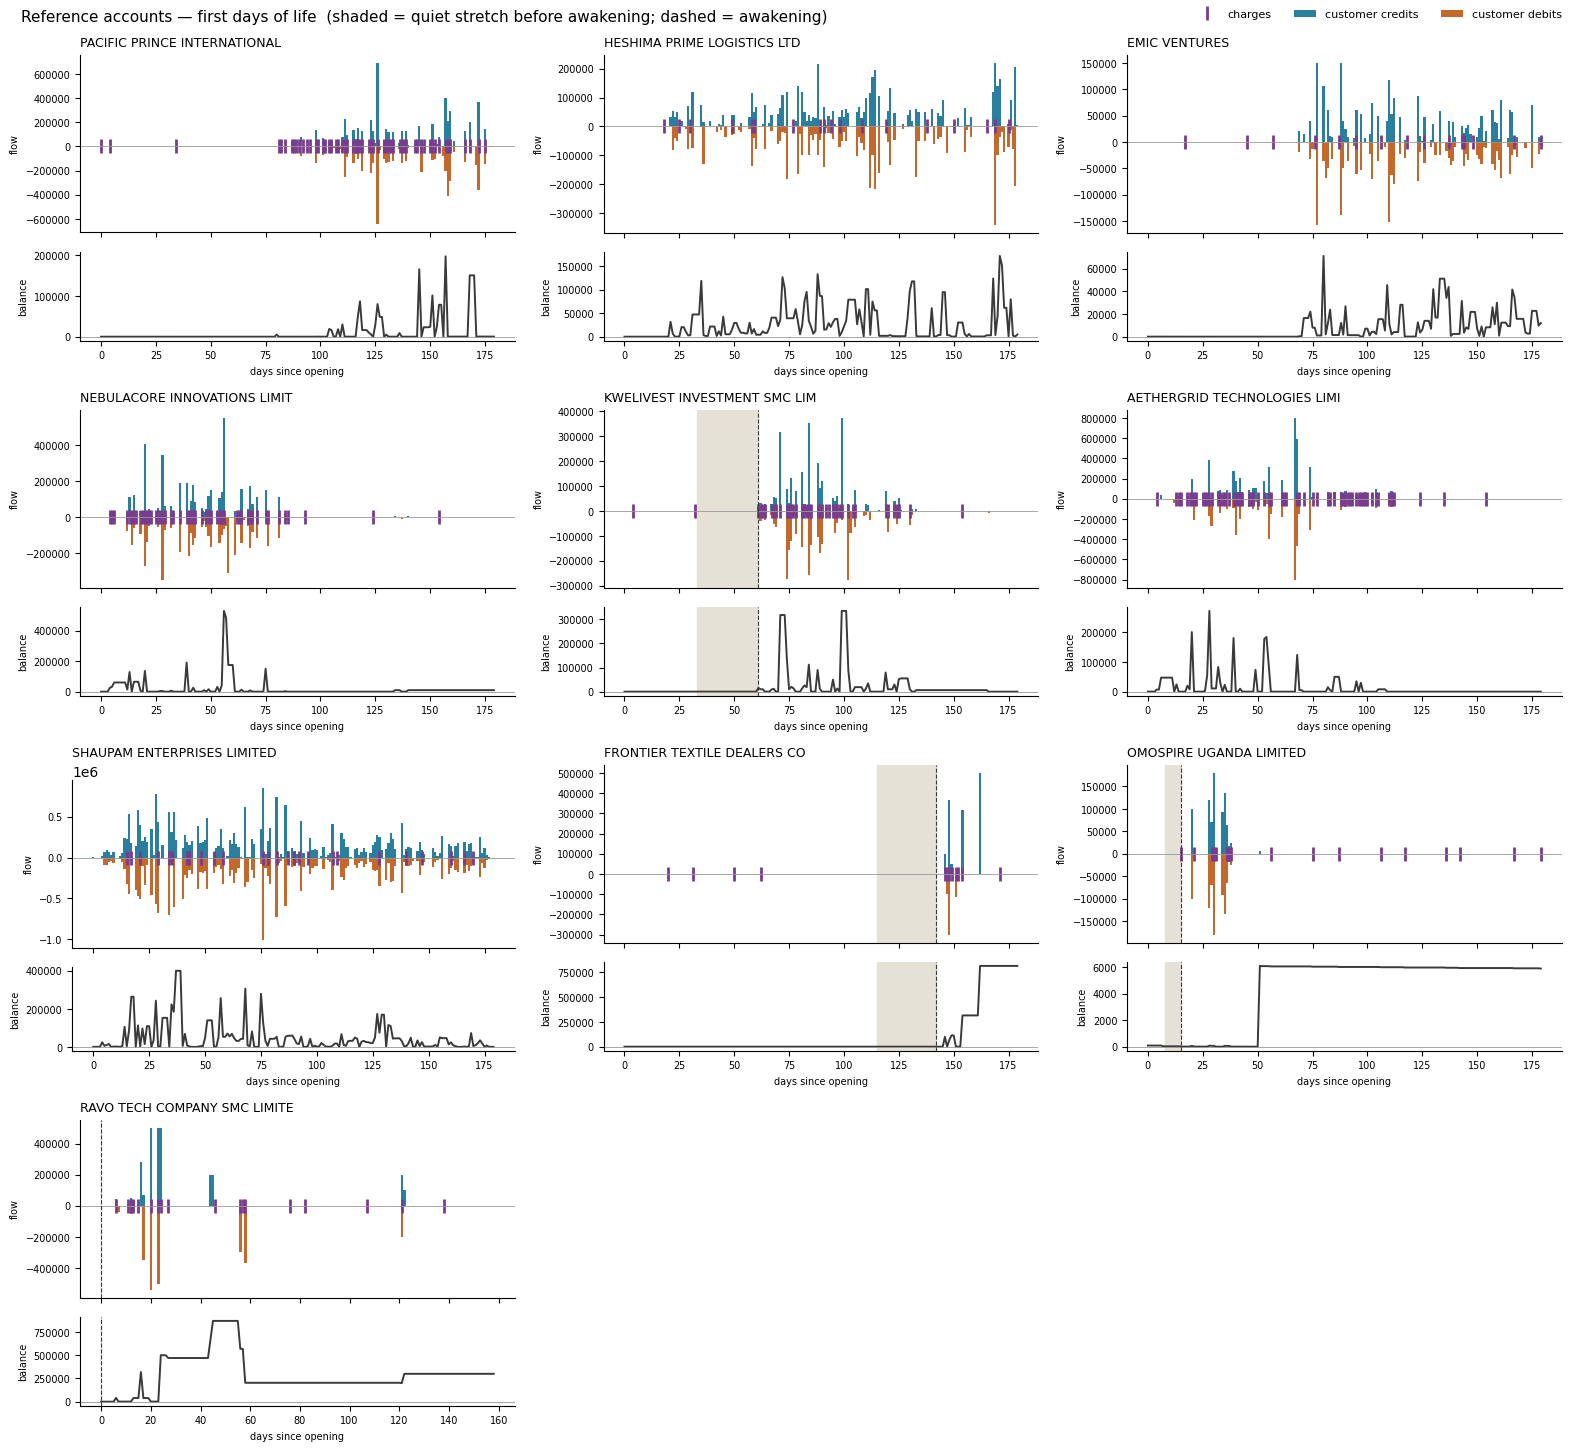

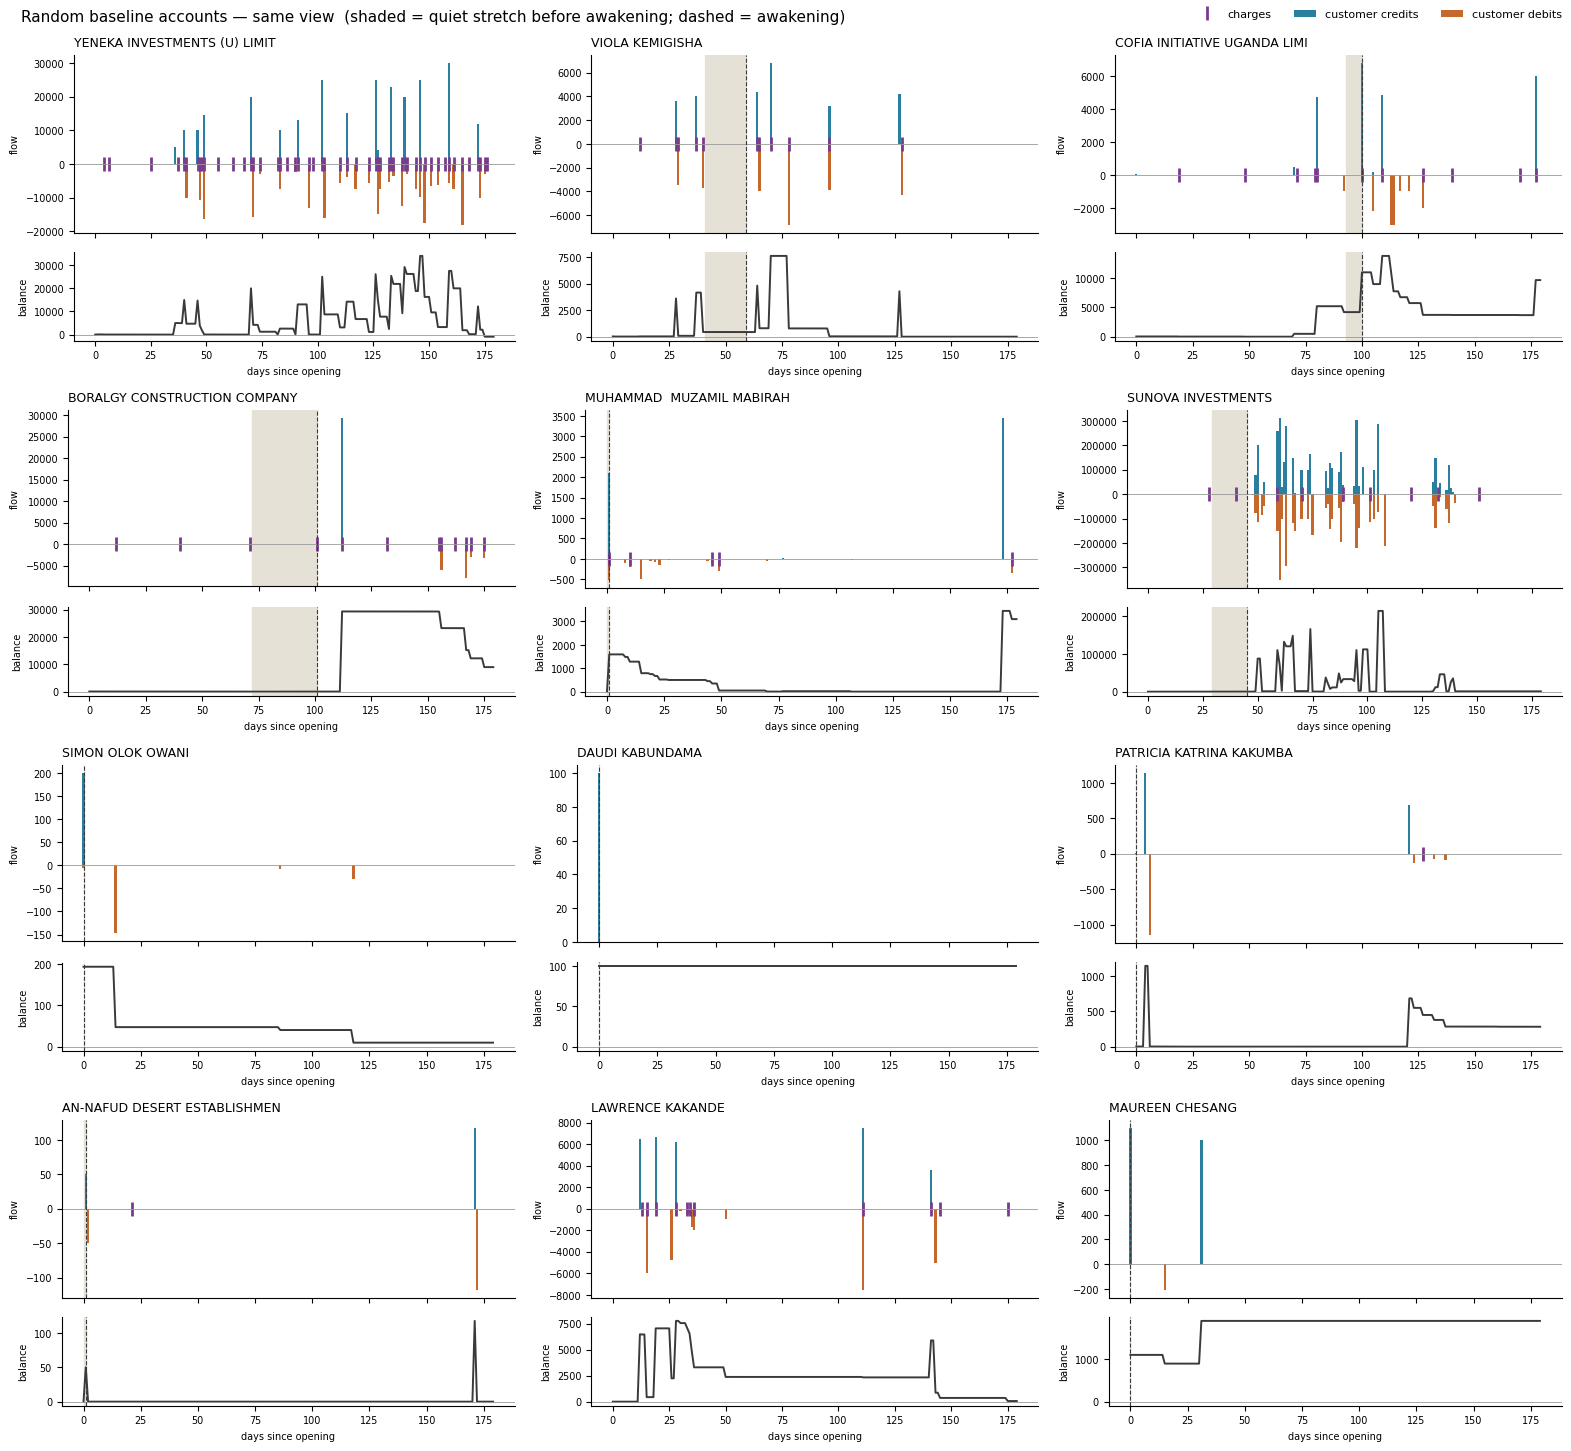

In [18]:
COL = {"cr": "#2a7f9e", "dr": "#c4682b", "chg": "#7a3b8f", "bal": "#3a3a3a", "quiet": "#e6e1d6"}

def plot_panels(acids, title, fname, ncols=3):
    acids = list(acids)
    if not acids:
        print(f"Nothing to plot for {title}"); return
    nrows = int(np.ceil(len(acids) / ncols))
    fig = plt.figure(figsize=(5.2 * ncols, 3.6 * nrows), constrained_layout=True)
    subs = np.atleast_1d(fig.subfigures(nrows, ncols)).ravel()
    s_idx = summary.set_index("ACID")
    for sf, acid in zip(subs, acids):
        d, s = timelines[acid], s_idx.loc[acid]
        ax, axb = sf.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [2, 1]})
        ax.bar(d.index, d.customer_cr, color=COL["cr"], width=1.0, label="customer credits")
        ax.bar(d.index, -d.customer_dr, color=COL["dr"], width=1.0, label="customer debits")
        chg = d.index[d.charge_dr > 0]
        ax.plot(chg, np.zeros(len(chg)), "|", color=COL["chg"], ms=10, mew=2, label="charges")
        ax.axhline(0, color="#999", lw=.6)
        axb.plot(d.index, d.balance, color=COL["bal"], lw=1.4)
        axb.axhline(0, color="#999", lw=.6)
        if pd.notna(s.awakening_day):
            a, qd = int(s.awakening_day), int(s.quiet_before_awake)
            for x in (ax, axb):
                x.axvspan(a - qd, a, color=COL["quiet"], zorder=0)
                x.axvline(a, color=COL["bal"], lw=.8, ls="--")
        tag = "STAGING" if s.staging else ""
        ax.set_title(f"{str(s.ACCT_NAME)[:28]}  {tag}", fontsize=9, loc="left")
        ax.tick_params(labelsize=7); axb.tick_params(labelsize=7)
        ax.set_ylabel("flow", fontsize=7); axb.set_ylabel("balance", fontsize=7)
        axb.set_xlabel("days since opening", fontsize=7)
        for x in (ax, axb):
            x.spines[["top", "right"]].set_visible(False)
    for sf in subs[len(acids):]:
        sf.set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper right", ncols=3, fontsize=8, frameon=False)
    fig.suptitle(title + "  (shaded = quiet stretch before awakening; dashed = awakening)", fontsize=11, x=0.01, ha="left")
    fig.savefig(OUT / fname, dpi=130)
    plt.show()

plot_panels(ref.sort_values("ACCT_OPN_DATE").ACID, "Reference accounts — first days of life", "reference_timelines.png")
plot_panels(base.sample(n=min(12, len(base)), random_state=RANDOM_SEED).ACID,
            "Random baseline accounts — same view", "baseline_timelines.png")

## 9. Focus account

In [19]:
focus = summary[summary.ACCT_NAME.str.upper().str.contains(FOCUS_NAME, na=False)]
if focus.empty:
    print(f"No account name contains '{FOCUS_NAME}'")
else:
    for acid in focus.ACID:
        d = timelines[acid]
        print(summary.set_index("ACID").loc[acid, ["ACCT_NAME", "FORACID", "group"] + METRICS + ["staging"]].to_string())
        active = d[(d.cust_n > 0) | (d.charge_dr > 0) | (d.gl_cr + d.gl_dr > 0)]
        display(active[["customer_cr", "customer_dr", "charge_dr", "gl_cr", "gl_dr", "balance"]].head(40).round(2))

ACCT_NAME                 FRONTIER TEXTILE DEALERS CO LIMITED
FORACID                                         9030027282317
group                                               reference
first_cr_day                                                0
first_dr_day                                                0
cr_to_dr_gap                                                0
active_days                                                16
turnover_first30_share                               0.000062
charge_share_early                                   0.797462
fee_erosion                                               0.0
longest_quiet                                              31
awakening_day                                             142
quiet_before_awake                                         27
staging                                                 False


,customer_cr,customer_dr,charge_dr,gl_cr,gl_dr,balance
day,,,,,,
0,100.0,11.50,0.00,88.5,88.5,88.50
20,0.0,2.55,17.00,0.0,0.0,68.95
31,0.0,0.00,20.70,0.0,0.0,48.25
50,0.0,2.55,17.00,0.0,0.0,28.70
62,0.0,0.00,20.70,0.0,0.0,8.00
82,0.0,2.55,0.00,0.0,0.0,5.45
94,0.0,2.70,0.00,0.0,0.0,2.75
114,0.0,2.55,0.00,0.0,0.0,0.20
142,103.0,0.00,0.00,0.0,0.0,103.20


## 10. Export

In [20]:
summary.to_csv(OUT / "early_metrics.csv", index=False)
comp.to_csv(OUT / "reference_vs_baseline.csv")
pd.concat({a: d for a, d in timelines.items() if a in set(ref.ACID)}, names=["ACID"]).to_csv(OUT / "reference_daily_timelines.csv")
print("Saved to", OUT.resolve())

Saved to /home/A270827/experiments/AML/outputs/early_signals


## 11. Gate — what to decide from this

| What you see | Reading | Next step |
|---|---|---|
| Staging in roughly half or more of reference accounts, clearly rarer in baseline, and the timelines visibly agree | Real, early, discriminative signal | **Experiment 2:** turn the staging metrics into features; check separation with the Fisher score |
| Staging common in reference accounts but **also** common in baseline | Real but not distinctive on its own (dormant-funded legit accounts) | Combine with onboarding / network signals rather than use alone |
| Staging rare among reference accounts (FRONTIER-like only) | FRONTIER is a one-off | Prioritise onboarding and shared-party signals at account opening |

Other things worth noting while reading the panels:
- Does `charge_share_early` or `fee_erosion` separate the groups even when the full staging flag doesn't?
- Are awakenings driven by one large inbound credit or many small ones (the dispersion signal from the Fisher work)?
- Do any baseline accounts look like the reference panels? Note their FORACIDs — they're the false positives an early-warning tier would raise.

With ~10 reference accounts, treat every number here as directional evidence, not a result.

In [21]:
summary["ACCT_NAME"] = [
    n if FOCUS_NAME in str(n).upper()
    else f"{'REF' if g == 'reference' else 'BASE'}{i:03d}"
    for i, (n, g) in enumerate(zip(summary.ACCT_NAME, summary.group))
]
summary = summary.drop(columns=["FORACID", "CIF_ID"])

In [23]:
summary

,ACID,first_cr_day,first_cr_amt,first_dr_day,cr_to_dr_gap,active_days,turnover_window,turnover_first30_share,charge_share_early,fee_erosion,longest_quiet,awakening_day,quiet_before_awake,staging,ACCT_NAME,ACCT_OPN_DATE,ACCT_CLS_FLG,group,observed_days
0,UG5930217,5,102.21,5,0,46,91200.05,0.377093,0.004123,0.0,26,66,8,False,BASE000,2024-01-18,N,baseline,180
1,UG5945201,0,100.0,0,0,3,165.3,0.637024,0.0,0.0,45,0,0,False,BASE001,2024-02-19,N,baseline,180
2,UG5975960,128,5000.0,0,-128,2,10000.0,0.5,0.0,0.0,127,0,0,False,BASE002,2024-04-24,N,baseline,180
3,UG5985919,18,1095.5,0,-18,11,280410.62,0.717147,0.023481,0.0,31,0,0,False,BASE003,2024-05-13,Y,baseline,180
4,UG6022932,0,13.18,6,6,9,2193.18,0.439171,0.049266,0.872534,31,NaN,NaN,False,BASE004,2024-07-23,N,baseline,180
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
205,UG6237428,44,3729.73,0,-44,6,54544.2,0.605946,0.019302,0.0,43,0,0,False,BASE205,2025-10-15,Y,baseline,180
206,UG6247737,1,100.0,2,1,10,2971.55,0.035396,0.0,0.0,106,43,40,True,BASE206,2025-11-07,N,baseline,180
207,UG6268493,0,4710.0,0,0,32,37707.32,0.216542,0.017507,0.0,30,151,10,False,BASE207,2025-12-15,N,baseline,180
208,UG6313249,2,34344.0,13,11,46,3918090.96,0.17951,0.000383,0.0,19,NaN,NaN,False,BASE208,2026-03-12,N,baseline,180
